<a href="https://colab.research.google.com/github/rlaj0730-design/deep-learning-study/blob/main/ex01_%EB%94%A5%EB%9F%AC%EB%8B%9D_%EA%B8%B0%EB%B0%98_%EC%9D%B4%EB%AF%B8%EC%A7%80_%EB%B6%84%EB%A5%98.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 현재 작업 디렉토리 확인
!pwd

/content


In [ ]:
# 작업 디렉토리 변경
%cd "/content/drive/MyDrive/Colab Notebooks/딥러닝 기초"

/content/drive/MyDrive/Colab Notebooks/딥러닝 기초


In [ ]:
!pwd

/content/drive/MyDrive/Colab Notebooks/딥러닝 기초


### 학습목표
- 딥러닝 프레임워크 활용해보기
- 딥러닝 모델링 순서 체험 (데이터로드 > 전처리 > 학습 > 평가)

In [ ]:
# 데이터로딩
import numpy as np
from tqdm import tqdm # 반복문 작업의 진척률을 시각화하는 도구
from tensorflow.keras.utils import image_dataset_from_directory # 폴더에서 이미지를 불러오는 도구
import matplotlib.pyplot as plt # 시각화 도구
# 전처리
from tensorflow.keras.applications.inception_v3 import preprocess_input # 이미지 전처리 도구
from tensorflow.keras.applications import InceptionV3 # 이미지특징 추출 도구
# 학습
from tensorflow.keras.models import Sequential # 인공신경망을 구성하는 기본 틀
from tensorflow.keras.layers import Dense # 뇌세포를 담당하는 도구
from tensorflow.keras.layers import InputLayer # 인공신경망의 입력모양을 지정하는 도구
#평가
from sklearn.metrics import classification_report # 분류모델의 성능을 평가하는 도구

### 1. 데이터 로드

In [ ]:
# 현재 작업디렉토리 내부 확인
!ls

 data  'ex00_머신러닝 개념 복습.ipynb'	'ex01_딥러닝 기반 이미지 분류.ipynb'


In [ ]:
# 압축풀기(리눅스 명령어 사용)
# !unzip "./data/animal_train.zip" -d "./data/train/"

In [ ]:
!ls "./data/train"

butterfly  cat	chicken  cow  dog


In [ ]:
# 폴더에서 이미지데이터 정보 불러오기
train_data = image_dataset_from_directory(
    directory = "./data/train", # 읽어들일 경로
    labels='inferred', # 폴더명을 인식해서 정답으로 지정
    label_mode='int', # 정답을 지정된 숫자 형식으로 변환
    color_mode='rgb', # 이미지를 컬러 채널로 로딩
    batch_size=32, # 한번에 처리하는 데이터 수 (메모리 관련)
    image_size=(256, 256) # 이미지 리사이징 크기 (서로 다른 크기의 이미지를 통일)
)

Found 2500 files belonging to 5 classes.


In [ ]:
# 클래스 이름 확인
train_data.class_names

['butterfly', 'cat', 'chicken', 'cow', 'dog']

In [ ]:
# 훈련용 데이터가 저장될 리스트 생성
X_train = []
y_train = []

In [ ]:
# 반복문을 이용해서 데이터 (사진, 정답라벨) 읽기
for img, label in tqdm(train_data.as_numpy_iterator()) :
  X_train.append(img) # 32개씩 이미지 묶음을 리스트에 저장
  y_train.append(label) # 32개씩 정답 묶음을 리스트에 저장

79it [04:58,  3.78s/it]


In [ ]:
# 32개씩 묶은 넘파이 배열을 하나로 통합
X_train_final = np.concat(X_train)
y_train_final = np.concat(y_train)

In [ ]:
X_train_final.shape, y_train_final.shape

((2500, 256, 256, 3), (2500,))

In [ ]:
# !unzip -q ./data/animal_test.zip -d ./data

In [ ]:
!ls "./data/animal_test"

butterfly  cat	chicken  cow  dog


In [ ]:
test_data = image_dataset_from_directory(
    directory="./data/animal_test",
    labels="inferred",
    label_mode="int",
    class_names=train_data.class_names,
    color_mode="rgb",
    batch_size=32,
    image_size=(256, 256),
    shuffle=False
)

Found 500 files belonging to 5 classes.


In [ ]:
X_test = []
y_test = []

for img, label in tqdm(test_data.as_numpy_iterator()):
    X_test.append(img)
    y_test.append(label)

X_test_final = np.concatenate(X_test)
y_test_final = np.concatenate(y_test)

print(X_test_final.shape, y_test_final.shape)

16it [01:06,  4.18s/it]

(500, 256, 256, 3) (500,)


In [ ]:
# 이미지데이터 확인하기
X_train_final[0]

array([[[202.74219 , 208.74219 , 208.74219 ],
        [199.22656 , 205.22656 , 205.22656 ],
        [197.      , 203.      , 203.      ],
        ...,
        [126.57031 , 129.57031 , 110.57031 ],
        [127.      , 130.      , 111.      ],
        [127.      , 130.      , 111.      ]],

       [[202.74219 , 207.92989 , 210.36679 ],
        [199.45567 , 205.22656 , 205.9139  ],
        [197.50682 , 203.      , 204.52046 ],
        ...,
        [126.95216 , 129.95216 , 110.95216 ],
        [127.      , 130.      , 111.      ],
        [127.8123  , 130.8123  , 111.8123  ]],

       [[203.55664 , 208.57259 , 212.26921 ],
        [200.29883 , 205.43654 , 208.23338 ],
        [198.38477 , 203.4645  , 206.6898  ],
        ...,
        [127.46449 , 130.4645  , 111.46449 ],
        [127.81445 , 130.81445 , 111.81445 ],
        [127.984055, 130.98405 , 111.984055]],

       ...,

       [[142.4554  , 132.4554  , 105.4554  ],
        [131.88966 , 121.88966 ,  94.88966 ],
        [128.7784  , 1

array([[[202, 208, 208],
        [199, 205, 205],
        [197, 203, 203],
        ...,
        [126, 129, 110],
        [127, 130, 111],
        [127, 130, 111]],

       [[202, 207, 210],
        [199, 205, 205],
        [197, 203, 204],
        ...,
        [126, 129, 110],
        [127, 130, 111],
        [127, 130, 111]],

       [[203, 208, 212],
        [200, 205, 208],
        [198, 203, 206],
        ...,
        [127, 130, 111],
        [127, 130, 111],
        [127, 130, 111]],

       ...,

       [[142, 132, 105],
        [131, 121,  94],
        [128, 118,  91],
        ...,
        [176, 165, 137],
        [177, 166, 138],
        [179, 168, 140]],

       [[148, 138, 110],
        [138, 128, 101],
        [134, 123,  96],
        ...,
        [174, 163, 135],
        [176, 165, 137],
        [177, 166, 138]],

       [[147, 136, 108],
        [143, 132, 104],
        [139, 128, 100],
        ...,
        [172, 162, 135],
        [173, 163, 136],
        [175, 165, 138]]], shape=(256, 256, 3), dtype=uint8)
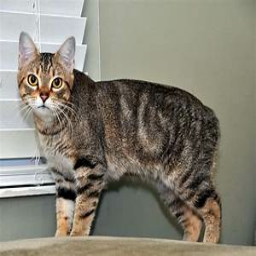

In [ ]:
X_train_final[0].astype("uint8")

In [ ]:
# 정답데이터 확인
y_train_final[0]

np.int32(1)

### 2. 전처리
- 이미지 데이터는 복잡성이 높기 때문에 주요 특징을 추출하고 불필요한 정보를 제거하는 전처리가 필수 (CNN계열)
- 사전에 미리 학습된 도구인 inceptionV3를 사용

In [ ]:
# 오리지날 이미지 픽셀 값 range 확인
print("픽셀의 최대 값 : ", X_train_final.max())
print("픽셀의 최소 값 : ", X_train_final.min())

픽셀의 최대 값 :  255.0
픽셀의 최소 값 :  0.0


In [ ]:
# InceptionV3가 요구하는 데이터범위로 스케일링 실시
X_train_preprocced = preprocess_input(X_train_final)
X_test_preprocced = preprocess_input(X_test_final)

In [ ]:
# 변환된 이미지 픽셀 값 range 확인
print("픽셀의 최대 값 : ", X_train_preprocced.max())
print("픽셀의 최소 값 : ", X_train_preprocced.min())

픽셀의 최대 값 :  1.0
픽셀의 최소 값 :  -1.0


In [ ]:
# 이미지 전처리(특징추출기) 도구 생성
imageEmbedding = InceptionV3(
    include_top=False, # 분류기 부분을 제거하고 다운로드 받도록 설정
    weights='imagenet', # 1000가지를 구분하는 데이터셋이 학습된 상태로 다운로드
    input_shape=(256,256,3), # InceptionV3에 넣는 이미지의 모양을 셋팅
    pooling='avg' # 추출데이터를 최종적으로 평균을 내서 반복
)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# 이미지 데이터를 InceptionV3에 통과시켜서 전처리하기
X_train_embedding = imageEmbedding.predict(X_train_preprocced)
X_test_embedding = imageEmbedding.predict(X_test_preprocced)

79/79 ━━━━━━━━━━━━━━━━━━━━ 361s 463ms/step
16/16 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step


In [ ]:
X_train_embedding.shape, X_test_embedding.shape

((2500, 2048), (500, 2048))

### 3.학습
- 임베딩 : 오리지날 데이터의 정보를 추출해 지정된 벡터공간에 이식하는 기술
- InceptionV3를 활용한 이미지 임베딩 결과물 (2048개 특성데이터)을 학습시켜보자

In [ ]:
# 모델설계
my_animal_model = Sequential() # 인공신경망 틀 생성
my_animal_model.add(InputLayer(shape=(2048,))) # 신경망에 들어오는 데이터 모양 지정
my_animal_model.add(Dense(units=100, activation='relu')) # 뇌세포 붙이기
my_animal_model.add(Dense(units=200, activation='relu')) # 뇌세포 붙이기
my_animal_model.add(Dense(units=300, activation='relu')) # 뇌세포 붙이기
my_animal_model.add(Dense(units=200, activation='relu')) # 뇌세포 붙이기
my_animal_model.add(Dense(units=100, activation='relu')) # 뇌세포 붙이기
my_animal_model.add(Dense(units=5, activation='softmax')) # 출력형태 지정

In [ ]:
# 학습방법 설정
my_animal_model.compile(loss="sparse_categorical_crossentropy", # 모델의 잘못된 정도를 측정하는 손실함수 지정
                        optimizer="adam", # 업데이트 방향을 알려주는 알고리즘 지정
                        metrics=["accuracy"]) # 평가방법 지정(정확도)

In [ ]:
# 모델학습
my_animal_model.fit(X_train_embedding, #문제
                    y_train_final, # 정답
                    epochs = 10) # 학습 반복 횟수

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.9372 - loss: 0.2095
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9924 - loss: 0.0287
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9864 - loss: 0.0381
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9928 - loss: 0.0195
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9968 - loss: 0.0110
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0015
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 2.8143e-04
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 6.3018e-05
Epoch 9/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 1.8232e-05
Epoch 10/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 1.3793e-05


### 4. 평가

In [ ]:
predict = my_animal_model.predict(X_test_embedding)

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step


In [ ]:
predict.shape

(500, 5)

In [ ]:
# 예측 값 하나 확인하기
predict[0]

array([1.0000000e+00, 2.2300467e-12, 1.0838468e-08, 4.0669104e-11,
       5.4472222e-09], dtype=float32)

In [ ]:
# 최대 확률 값을 가진 인덱스 번호 뽑기
np.argmax(predict[0])

np.int64(0)

In [ ]:
y_test_final[0]

np.int32(0)

In [ ]:
# 500개의 예측 확률을 클래스 번호로 변경
y_pred = predict.argmax(1)
y_pred

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 1, 1, 4, 1,
       1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 4, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3,

In [ ]:
print(classification_report(y_test_final, y_pred)) # 실제값과 모델의 예측값 넣기

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       100
           1       0.99      0.97      0.98       100
           2       1.00      0.97      0.98       100
           3       1.00      0.97      0.98       100
           4       0.93      1.00      0.97       100

    accuracy                           0.98       500
   macro avg       0.98      0.98      0.98       500
weighted avg       0.98      0.98      0.98       500

